In [39]:
import numpy as np

bits = np.array([1, 0, 1, 1, 0, 0, 1, 0])

print(bits)

[1 0 1 1 0 0 1 0]


In [40]:
# Group our binary data into pairs
bit_pairs = bits.reshape(-1, 2)

# Display the pairs
print(bit_pairs)

[[1 0]
 [1 1]
 [0 0]
 [1 0]]


In [41]:
# Convert binary pairs into QPSK symbols

I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

# Combine I and Q into complex symbols
qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Display the symbols
print(qpsk_symbols)

[-0.70710678+0.70710678j -0.70710678-0.70710678j  0.70710678+0.70710678j
 -0.70710678+0.70710678j]


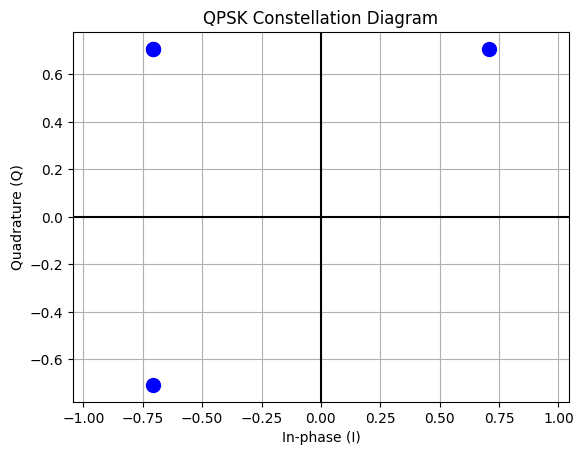

In [42]:
import matplotlib.pyplot as plt

# Plot our QPSK symbols
plt.scatter(qpsk_symbols.real, qpsk_symbols.imag,
            color='blue', s=100)

# Draw the horizontal and vertical axes
plt.axhline(0, color='black')
plt.axvline(0, color='black')

# Label the axes
plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")

# Add a title and grid
plt.title("QPSK Constellation Diagram")
plt.grid(True)

# Set the graph boundaries
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)

# Keep equal spacing on both axes
plt.axis('equal')

# Display the graph
plt.show()

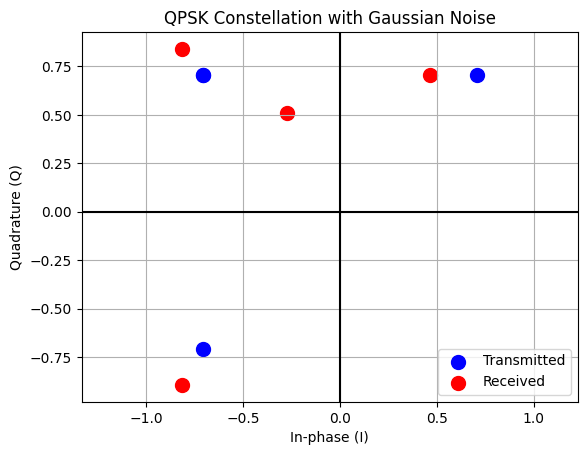

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Set the noise level
noise_std = 0.3

# Generate random Gaussian noise
noise = noise_std * (
    np.random.randn(len(qpsk_symbols)) +
    1j * np.random.randn(len(qpsk_symbols))
)

# Add noise to our transmitted QPSK symbols
received_symbols = qpsk_symbols + noise

# Plot the original transmitted symbols
plt.scatter(qpsk_symbols.real, qpsk_symbols.imag,
            color='blue', label='Transmitted', s=100)

# Plot the received symbols after adding noise
plt.scatter(received_symbols.real, received_symbols.imag,
            color='red', label='Received', s=100)

# Draw the axes
plt.axhline(0, color='black')
plt.axvline(0, color='black')

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("QPSK Constellation with Gaussian Noise")
plt.legend()
plt.grid(True)
plt.axis('equal')

plt.show()

In [44]:
# QPSK Demodulation

# Recover the first bit from the I component
received_I = (received_symbols.real < 0).astype(int)

# Recover the second bit from the Q component
received_Q = (received_symbols.imag < 0).astype(int)

# Combine the recovered bits into pairs
received_bit_pairs = np.column_stack((received_I, received_Q))

# Convert the pairs back into a sequence of bits
received_bits = received_bit_pairs.flatten()

# Display the results
print("Original bits: ", bits)
print("Received bits: ", received_bits)

Original bits:  [1 0 1 1 0 0 1 0]
Received bits:  [1 0 1 1 0 0 1 0]


In [45]:
# Step 7: Calculate Bit Error Rate (BER)

# Count the number of incorrect bits
bit_errors = np.sum(bits != received_bits)

# Calculate the bit error rate
ber = bit_errors / len(bits)

# Display the results
print("Total transmitted bits:", len(bits))
print("Number of bit errors:", bit_errors)
print("Bit Error Rate:", ber)

Total transmitted bits: 8
Number of bit errors: 0
Bit Error Rate: 0.0


Noise: 0.1, BER: 0.00000
Noise: 0.2, BER: 0.00015
Noise: 0.3, BER: 0.01040
Noise: 0.4, BER: 0.03700
Noise: 0.5, BER: 0.08230
Noise: 0.6, BER: 0.11720
Noise: 0.7, BER: 0.15465
Noise: 0.8, BER: 0.19155
Noise: 0.9, BER: 0.21615
Noise: 1.0, BER: 0.24215


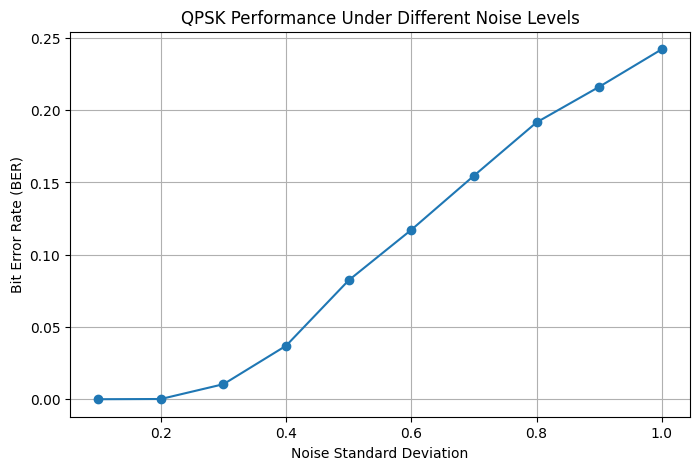

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate 20,000 random binary bits
num_bits = 20000
bits = np.random.randint(0, 2, num_bits)

# Step 2: Group bits into pairs
bit_pairs = bits.reshape(-1, 2)

# Step 3: QPSK Modulation
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Step 4: Define different noise levels
noise_levels = np.arange(0.1, 1.1, 0.1)

# Store BER results
ber_results = []

# Step 5: Test each noise level
for noise_std in noise_levels:

    # Generate Gaussian noise
    noise = noise_std * (
        np.random.randn(len(qpsk_symbols)) +
        1j * np.random.randn(len(qpsk_symbols))
    )

    # Add noise to transmitted symbols
    received_symbols = qpsk_symbols + noise

    # Step 6: QPSK Demodulation
    received_I = (received_symbols.real < 0).astype(int)
    received_Q = (received_symbols.imag < 0).astype(int)

    # Recover original bits
    received_pairs = np.column_stack((received_I, received_Q))
    received_bits = received_pairs.flatten()

    # Step 7: Calculate Bit Error Rate
    bit_errors = np.sum(bits != received_bits)
    ber = bit_errors / num_bits

    ber_results.append(ber)

    print(f"Noise: {noise_std:.1f}, BER: {ber:.5f}")

# Step 8: Plot BER against noise level
plt.figure(figsize=(8, 5))

plt.plot(noise_levels, ber_results, marker='o')

plt.xlabel("Noise Standard Deviation")
plt.ylabel("Bit Error Rate (BER)")
plt.title("QPSK Performance Under Different Noise Levels")

plt.grid(True)
plt.show()

Eb/N0: 0 dB | Simulated BER: 0.079265 | Theoretical BER: 0.078650
Eb/N0: 1 dB | Simulated BER: 0.056075 | Theoretical BER: 0.056282
Eb/N0: 2 dB | Simulated BER: 0.038030 | Theoretical BER: 0.037506
Eb/N0: 3 dB | Simulated BER: 0.022670 | Theoretical BER: 0.022878
Eb/N0: 4 dB | Simulated BER: 0.012390 | Theoretical BER: 0.012501
Eb/N0: 5 dB | Simulated BER: 0.006050 | Theoretical BER: 0.005954
Eb/N0: 6 dB | Simulated BER: 0.002455 | Theoretical BER: 0.002388
Eb/N0: 7 dB | Simulated BER: 0.000810 | Theoretical BER: 0.000773
Eb/N0: 8 dB | Simulated BER: 0.000170 | Theoretical BER: 0.000191
Eb/N0: 9 dB | Simulated BER: 0.000025 | Theoretical BER: 0.000034
Eb/N0: 10 dB | Simulated BER: 0.000015 | Theoretical BER: 0.000004


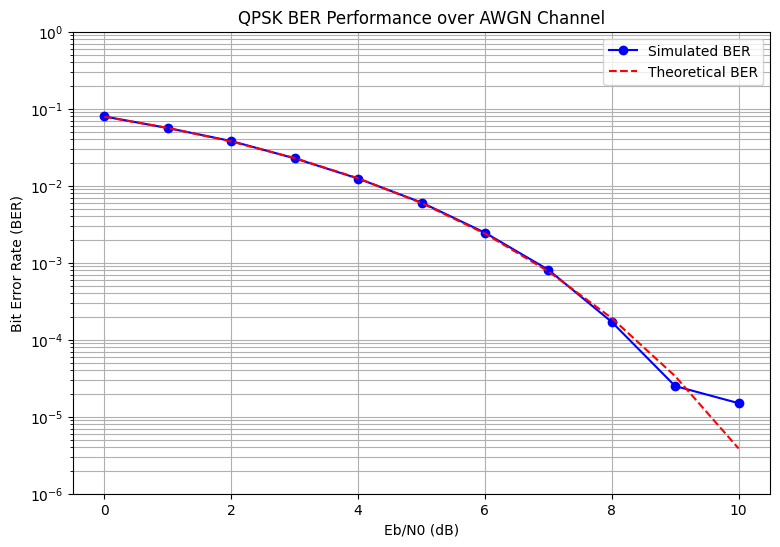

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# STEP 9: SIMULATED VS THEORETICAL BER

# Generate 200,000 random bits
num_bits = 200000
bits = np.random.randint(0, 2, num_bits)

# Group bits into pairs
bit_pairs = bits.reshape(-1, 2)

# QPSK Modulation
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Define Eb/N0 values
EbN0_dB = np.arange(0, 11, 1)

simulated_ber = []
theoretical_ber = []

# Test different signal-to-noise ratios
for snr_db in EbN0_dB:

    EbN0 = 10 ** (snr_db / 10)

    # Calculate noise standard deviation
    noise_std = np.sqrt(1 / (4 * EbN0))

    # Generate Gaussian noise
    noise = noise_std * (
        np.random.randn(len(qpsk_symbols))
        + 1j * np.random.randn(len(qpsk_symbols))
    )

    # Add noise to transmitted symbols
    received_symbols = qpsk_symbols + noise

    # QPSK Demodulation
    received_I = (received_symbols.real < 0).astype(int)
    received_Q = (received_symbols.imag < 0).astype(int)

    # Recover binary bits
    received_pairs = np.column_stack(
        (received_I, received_Q)
    )

    received_bits = received_pairs.flatten()

    # Calculate simulated BER
    errors = np.sum(bits != received_bits)
    ber = errors / num_bits

    simulated_ber.append(ber)

    # Calculate theoretical BER
    theory = 0.5 * erfc(np.sqrt(EbN0))
    theoretical_ber.append(theory)

    print(
        f"Eb/N0: {snr_db} dB | "
        f"Simulated BER: {ber:.6f} | "
        f"Theoretical BER: {theory:.6f}"
    )

# Plot BER comparison
plt.figure(figsize=(9, 6))

plt.semilogy(
    EbN0_dB,
    simulated_ber,
    'bo-',
    label="Simulated BER"
)

plt.semilogy(
    EbN0_dB,
    theoretical_ber,
    'r--',
    label="Theoretical BER"
)

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("QPSK BER Performance over AWGN Channel")

plt.legend()
plt.grid(True, which="both")
plt.ylim(1e-6, 1)

plt.show()

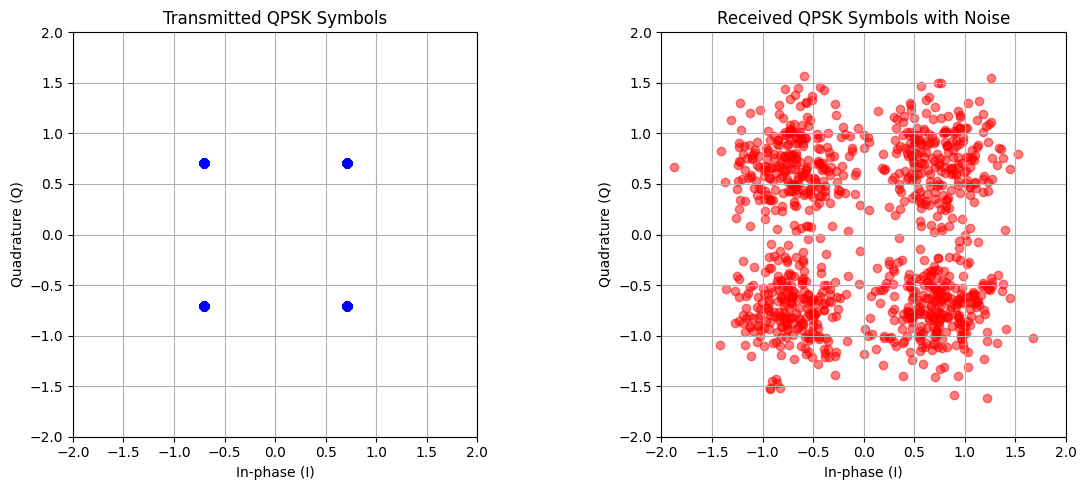

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# STEP 10: QPSK CONSTELLATION COMPARISON

# Generate 2000 random bits
num_bits = 2000
bits = np.random.randint(0, 2, num_bits)

# Group bits into pairs
bit_pairs = bits.reshape(-1, 2)

# QPSK modulation
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

transmitted_symbols = (I + 1j * Q) / np.sqrt(2)

# Simulate a noisy communication channel
noise_std = 0.3

noise = noise_std * (
    np.random.randn(len(transmitted_symbols))
    + 1j * np.random.randn(len(transmitted_symbols))
)

received_symbols = transmitted_symbols + noise

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Graph 1: Transmitted symbols
axes[0].scatter(
    transmitted_symbols.real,
    transmitted_symbols.imag,
    color="blue",
    alpha=0.5
)

axes[0].set_title("Transmitted QPSK Symbols")
axes[0].set_xlabel("In-phase (I)")
axes[0].set_ylabel("Quadrature (Q)")
axes[0].grid(True)

# Graph 2: Received symbols
axes[1].scatter(
    received_symbols.real,
    received_symbols.imag,
    color="red",
    alpha=0.5
)

axes[1].set_title("Received QPSK Symbols with Noise")
axes[1].set_xlabel("In-phase (I)")
axes[1].set_ylabel("Quadrature (Q)")
axes[1].grid(True)

# Use the same scale for both graphs
for ax in axes:
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# STEP 11: ORGANIZED QPSK SIMULATOR

# 1. Generate random binary data
def generate_bits(num_bits):
    return np.random.randint(0, 2, num_bits)


# 2. QPSK Modulation
def qpsk_modulate(bits):
    bit_pairs = bits.reshape(-1, 2)

    I = 1 - 2 * bit_pairs[:, 0]
    Q = 1 - 2 * bit_pairs[:, 1]

    symbols = (I + 1j * Q) / np.sqrt(2)

    return symbols


# 3. Add Gaussian noise
def add_noise(symbols, noise_std):
    noise = noise_std * (
        np.random.randn(len(symbols))
        + 1j * np.random.randn(len(symbols))
    )

    return symbols + noise


# 4. QPSK Demodulation
def qpsk_demodulate(received_symbols):
    I_bits = (received_symbols.real < 0).astype(int)
    Q_bits = (received_symbols.imag < 0).astype(int)

    bit_pairs = np.column_stack((I_bits, Q_bits))

    return bit_pairs.flatten()


# 5. Calculate Bit Error Rate
def calculate_ber(original_bits, received_bits):
    errors = np.sum(original_bits != received_bits)

    return errors / len(original_bits)


# 6. Run the complete QPSK simulation
num_bits = 20000
noise_std = 0.3

bits = generate_bits(num_bits)

transmitted_symbols = qpsk_modulate(bits)

received_symbols = add_noise(transmitted_symbols, noise_std)

received_bits = qpsk_demodulate(received_symbols)

ber = calculate_ber(bits, received_bits)

# Display results
print("QPSK Simulation Results")
print("-----------------------")
print("Total bits transmitted:", num_bits)
print("Bit errors:", np.sum(bits != received_bits))
print("Bit Error Rate:", ber)

QPSK Simulation Results
-----------------------
Total bits transmitted: 20000
Bit errors: 201
Bit Error Rate: 0.01005


In [50]:
# STEP 12: FINAL TESTING AND VALIDATION

num_bits = 20000

# Generate test data
test_bits = generate_bits(num_bits)

# Modulate the bits
test_symbols = qpsk_modulate(test_bits)

# Test different noise conditions
noise_levels = [0.0, 0.3, 0.7, 1.0]

for noise_level in noise_levels:

    # Add noise to the symbols
    noisy_symbols = add_noise(test_symbols, noise_level)

    # Demodulate the received symbols
    recovered_bits = qpsk_demodulate(noisy_symbols)

    # Calculate BER
    ber = calculate_ber(test_bits, recovered_bits)

    # Count errors
    errors = np.sum(test_bits != recovered_bits)

    print(f"Noise Level: {noise_level}")
    print(f"Bit Errors: {errors}")
    print(f"BER: {ber:.5f}")
    print("-----------------------")

Noise Level: 0.0
Bit Errors: 0
BER: 0.00000
-----------------------
Noise Level: 0.3
Bit Errors: 190
BER: 0.00950
-----------------------
Noise Level: 0.7
Bit Errors: 3207
BER: 0.16035
-----------------------
Noise Level: 1.0
Bit Errors: 4746
BER: 0.23730
-----------------------
